# 03 — Nettoyage et prétraitement (Partie 3 du TP)

**Consigne de la prof** : exploiter les constats de l'EDA pour nettoyer au mieux le dataset, **en justifiant chaque décision et l'ordre d'application des traitements**.

## Constats de l'EDA (partie 2) sur lesquels on s'appuie
| # | Constat (résultats réels du notebook 02) | Point d'EDA |
|---|---|---|
| A | 0 NaN après réduction 2×2, mais **12 cellules de la grille brute** sans aucune valeur (frontière nord), masquées par `coarsen().mean()` qui ignore les NaN | Valeurs manquantes |
| B | `ro` : variance < 0.01, **19,4 % de zéros**, skew 45, kurtosis 3 928 | Variabilité / asymétrie |
| C | `tp` (skew 5,8), `slhf` et `e` (skew −4,2) : ~15 à 16 % d'outliers IQR | Histogramme / boxplot |
| D | `ssr`, `str`, `sshf` incohérentes sur **2022-09 → 2024-02 (18 mois = 12,8 % des mois)** | Variation mensuelle |
| E | Corrélations \|ρ\| > 0.90 : `slhf`–`e` (1.00), `ro`–`tp` (0.98), `ssr`–`sshf` (−0.95) | Matrice de corrélation |
| F | Aucune variable normale → Spearman retenu ; classes de cible déséquilibrées (Froid ≈ 17 %) | Normalité / cible |

## Ordre d'application et pourquoi (règle générale : on corrige d'abord ce qui fausse les statistiques utilisées par les étapes suivantes)
1. **Intégrité et valeurs manquantes** — toute statistique suivante suppose un tableau complet.
2. **Incohérence temporelle (D)** — elle fausse moyennes, variances, corrélations (donc E) et la détection d'outliers : à traiter *avant* tout calcul de statistique.
3. **Cohérence physique** — règles déterministes et peu coûteuses, avant les transformations.
4. **Asymétrie et outliers (B, C)** — transformation des variables, avant la sélection pour que MI / importances soient calculées sur la représentation finale.
5. **Sélection de variables (B, E)** — corrélations et variances **recalculées sur données nettoyées** (étapes 2 à 4), sinon l'anomalie biaise ρ(ssr, sshf).
6. **Dérivation, cible, réduction du volume** — en dernier, car elles dépendent des variables retenues.
7. **Non fait ici volontairement : le scaling et le découpage train/test**, à faire dans les pipelines de l'étape 2 (ajusté sur le train seulement, pour éviter toute fuite d'information).

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_absolute_error
from IPython.display import display

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
RNG = np.random.default_rng(42)

_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents]
                     if (p/"data"/"processed"/"era5_algeria_masked_2x2_v2.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("era5_algeria_masked_2x2_v2.nc introuvable : exécutez d'abord le notebook 01.")
OUT = PROJECT_ROOT/"data"/"processed"
ds = xr.open_dataset(OUT/"era5_algeria_masked_2x2_v2.nc")
print("Dimensions :", dict(ds.sizes))

Dimensions : {'valid_time': 141, 'latitude': 95, 'longitude': 105}


## 0. Chargement, conversion des unités et construction du tableau (cellule × mois)

In [2]:
BASE = ["d2m","t2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]
ALL  = BASE + ["wind10_speed"]
conv = xr.Dataset(coords=ds.coords)
for v in ["d2m","t2m"]:               conv[v] = ds[v] - 273.15
for v in ["slhf","ssr","str","sshf"]: conv[v] = ds[v] / 86400.0
for v in ["ro","e","tp"]:             conv[v] = ds[v] * 1000.0
conv["sp"] = ds["sp"] / 100.0
conv["u10"], conv["v10"] = ds["u10"], ds["v10"]
conv["wind10_speed"] = np.hypot(ds["u10"], ds["v10"])

valid_cells = conv["t2m"].notnull().any("valid_time"); vm = valid_cells.values
times = pd.DatetimeIndex(conv.valid_time.values)
T, N = len(times), int(vm.sum())
months, years = times.month.values, times.year.values
ilat, ilon = np.where(vm)
ARR = {v: conv[v].values[:, vm].astype("float64") for v in ALL}          # (T, N) par variable
ARR_ORIG = {v: a.copy() for v, a in ARR.items()}                          # copie avant nettoyage (pour les graphiques avant/après)

df = pd.DataFrame({v: ARR[v].reshape(-1) for v in ALL})
df["time"]  = np.repeat(times.values, N); df["cell"] = np.tile(np.arange(N), T)
df["lat"]   = np.tile(conv.latitude.values[ilat], T); df["lon"] = np.tile(conv.longitude.values[ilon], T)
df["year"]  = np.repeat(years, N); df["month"] = np.repeat(months, N)
print(f"{len(df):,} lignes = {N:,} cellules × {T} mois | {times.min():%Y-%m} → {times.max():%Y-%m}")

764,784 lignes = 5,424 cellules × 141 mois | 2015-01 → 2026-09


## Étape 1 — Intégrité et valeurs manquantes (constat A)

**Règles du cours** : < 5 % de valeurs manquantes → imputation classique ; beaucoup de valeurs manquantes → modèle prédictif ; une colonne avec > 50 % de NaN est éliminée.

Dans le tableau réduit il y a 0 NaN. Mais ce n'est pas la preuve que la frontière est saine : une cellule 2×2 de bord peut n'être la moyenne que de 1 à 3 sous-cellules valides. On mesure donc, sur la grille brute, combien de sous-cellules valides contribuent à chaque cellule réduite (`n_sub`, de 1 à 4).

Les **zéros** de `ro` (19,4 %) sont-ils des valeurs manquantes codées 0 (le cours cite 0 parmi les représentations d'une valeur manquante) ou de vrais zéros ? On le teste : s'ils se concentrent dans le Sud aride, ce sont de vrais zéros.

In [3]:
print("NaN dans le tableau :", int(df[ALL].isna().sum().sum()))
n_sub = np.full(vm.shape, 4, dtype=int)
try:
    sys.path.insert(0, str(PROJECT_ROOT/"src"))
    from climate_utils import make_algeria_mask
    ds_raw = xr.open_dataset(PROJECT_ROOT/"data"/"raw"/"era5_algeria_raw.nc")
    mask, _ = make_algeria_mask(ds_raw, PROJECT_ROOT)
    ok_raw = ds_raw["t2m"].where(mask).notnull().any("valid_time")
    cnt = ok_raw.astype(float).coarsen(latitude=2, longitude=2, boundary="trim").sum().values
    assert cnt.shape == vm.shape, (cnt.shape, vm.shape)
    n_sub = np.where(vm, cnt, 4).astype(int)
    print("Grille brute : cellules dans le polygone sans aucune donnée :", int((mask & ~ok_raw).sum()))
    print("Cellules réduites construites avec < 4 sous-cellules valides :", int(((n_sub < 4) & vm).sum()),
          f"({100*((n_sub < 4) & vm).sum()/N:.2f} % des {N:,} cellules)")
    print("Répartition de n_sub :", dict(zip(*np.unique(n_sub[vm], return_counts=True))))
except Exception as err:
    print("Contrôle grille brute non exécuté :", type(err).__name__, "-", err)
df["n_sub"] = np.tile(n_sub[vm], T)

zr = (df["ro"] == 0).groupby(pd.cut(df["lat"], [0, 24, 28, 32, 40])).mean().mul(100).round(1)
print("\n% de ro = 0 par bande de latitude :"); display(zr.to_frame("% zéros"))

NaN dans le tableau : 0
Grille brute : cellules dans le polygone sans aucune donnée : 12
Cellules réduites construites avec < 4 sous-cellules valides : 225 (4.15 % des 5,424 cellules)
Répartition de n_sub : {np.int64(1): np.int64(74), np.int64(2): np.int64(78), np.int64(3): np.int64(73), np.int64(4): np.int64(5199)}

% de ro = 0 par bande de latitude :


,% zéros
lat,
"(0, 24]",33.2
"(24, 28]",25.1
"(28, 32]",17.5
"(32, 40]",1.8


**Décisions**
- Les cellules de bord à < 4 sous-cellules représentent une très petite fraction du domaine ; leur valeur est la moyenne des sous-cellules disponibles, une estimation légitime (équivalente à l'imputation classique par la moyenne du voisinage, applicable car ≪ 5 %). On les **conserve** et on ajoute la colonne `n_sub` pour pouvoir tester la sensibilité plus tard.
- Si les zéros de `ro` sont concentrés dans les bandes sud, ce sont de vrais zéros physiques (aucun ruissellement en climat désertique) : **on ne les traite pas comme manquants**.
- Garde-fou ci-dessous : si un NaN apparaissait (nouvelle extraction), il serait comblé par interpolation temporelle par cellule, puis les cellules entièrement vides seraient supprimées.

In [4]:
n_nan = sum(int(np.isnan(a).sum()) for a in ARR.values())
if n_nan:
    print(f"{n_nan} NaN → interpolation temporelle par cellule")
    for v in ALL:
        ARR[v] = pd.DataFrame(ARR[v]).interpolate(limit_direction="both").values
        df[v] = ARR[v].reshape(-1)
    df = df.dropna(subset=ALL)
else:
    print("Aucun NaN : garde-fou inactif.")

Aucun NaN : garde-fou inactif.


## Étape 2 — Incohérence temporelle ERA5 sur `ssr`, `str`, `sshf` (constat D)

**Pourquoi en premier après l'intégrité** : cette période fausse la moyenne, la variance, les corrélations (donc la décision sur `ssr`–`sshf`) et fait apparaître des « outliers » qui n'en sont pas.

**Vérification sur chaque cellule** (et pas seulement sur la moyenne régionale) : pour chaque variable, on compare la fenêtre 2022-09 → 2024-02 à la médiane du même mois calendaire des années hors fenêtre, en écarts-types résiduels. La part de cellules concernées dit si l'anomalie est généralisée (donc un problème de produit) ou locale.

In [5]:
ANOM_START, ANOM_END = "2022-09", "2024-02"          # fenêtre détectée par l'EDA (persistance >= 3 mois)
win   = (times >= pd.Timestamp(ANOM_START + "-01")) & (times <= pd.Timestamp(ANOM_END + "-01"))
clean = ~win
print(f"Fenêtre {ANOM_START} → {ANOM_END} : {int(win.sum())} mois sur {T} ({100*win.mean():.1f} %)")

def clim_median(a, rows):
    out = np.empty((12, a.shape[1]))
    for m in range(1, 13):
        out[m-1] = np.median(a[rows & (months == m)], axis=0)
    return out

rows = []
for v in ALL:
    a = ARR[v]; clim = clim_median(a, clean)
    sd = (a[clean] - clim[months[clean]-1]).std(axis=0)
    z = (a[win] - clim[months[win]-1]) / np.maximum(sd, 1e-9)
    rows.append({"variable": v, "% cellules atypiques (médiane |z|>3 sur la fenêtre)": 100*(np.median(np.abs(z), axis=0) > 3).mean(),
                 "rapport médian fenêtre/climatologie": np.median(a[win] / np.where(np.abs(clim[months[win]-1]) < 1e-9, np.nan, clim[months[win]-1]))})
diag = pd.DataFrame(rows).set_index("variable").sort_values(diag_col := "% cellules atypiques (médiane |z|>3 sur la fenêtre)", ascending=False)
display(diag.round(2))
V_ANOM = ["ssr", "str", "sshf"]
auto = diag.index[diag[diag_col] > 50].tolist()
print("Variables retenues comme incohérentes :", V_ANOM, "| détection automatique (> 50 % des cellules) :", auto)
if set(auto) != set(V_ANOM): print("!! La détection cellule par cellule diffère de l'EDA : vérifier avant de continuer.")

Fenêtre 2022-09 → 2024-02 : 18 mois sur 141 (12.8 %)


,% cellules atypiques (médiane |z|>3 sur la fenêtre),rapport médian fenêtre/climatologie
variable,,
str,100.00,0.49
ssr,100.00,0.54
sshf,85.36,0.48
e,0.53,0.46
slhf,0.53,0.46
t2m,0.00,1.02
d2m,0.00,0.93
ro,0.00,NaN
u10,0.00,1.05


Variables retenues comme incohérentes : ['ssr', 'str', 'sshf'] | détection automatique (> 50 % des cellules) : ['str', 'ssr', 'sshf']


**Choix de traitement** (cours : *delete value and handle as missing* puis imputation). Ici 12,8 % des mois sont à remplacer, donc **au-delà du seuil de 5 %** où l'imputation par la moyenne est recommandée : le cours préconise alors un **modèle prédictif**. On teste donc deux méthodes et on garde la meilleure *par validation temporelle* (années 2018 et 2019 mises de côté, années saines) :

1. **Climatologie** : médiane du même mois calendaire de la même cellule sur les années saines (équivalent « imputation intelligente » du cours : moyenne des échantillons de la même classe, ici même cellule × même mois).
2. **Modèle prédictif** (arbres boostés) : prédit la variable à partir de variables non touchées par l'anomalie (`t2m`, `d2m`, `sp`, `u10`, `v10`, `tp`, mois, lat, lon), ce qui conserve une partie de la variabilité interannuelle que la climatologie efface.

Les lignes imputées sont marquées (`imputed_rad`) pour pouvoir tester la sensibilité des modèles.

In [6]:
T_flat = {"win": np.repeat(win, N), "year": df["year"].values, "month": df["month"].values, "cell": df["cell"].values}
ang = 2*np.pi*df["month"].values/12
Xf = np.column_stack([df["t2m"], df["d2m"], df["sp"], df["u10"], df["v10"], np.log1p(df["tp"]),
                      np.sin(ang), np.cos(ang), df["lat"], df["lon"]])
VAL_YEARS = [2018, 2019]
val_rows = np.isin(T_flat["year"], VAL_YEARS) & ~T_flat["win"]
trn_rows = ~T_flat["win"] & ~val_rows
clean_t_val = clean & ~np.isin(years, VAL_YEARS)

res, choice, final_pred = [], {}, {}
for v in V_ANOM:
    y = ARR_ORIG[v].reshape(-1)
    tr = RNG.choice(np.where(trn_rows)[0], 250_000, replace=False)
    mdl = HistGradientBoostingRegressor(max_iter=200, random_state=42).fit(Xf[tr], y[tr])
    mae_m = mean_absolute_error(y[val_rows], mdl.predict(Xf[val_rows]))
    cl_val = clim_median(ARR_ORIG[v], clean_t_val)
    mae_c = mean_absolute_error(y[val_rows], cl_val[T_flat["month"][val_rows]-1, T_flat["cell"][val_rows]])
    best = "modèle" if mae_m < mae_c else "climatologie"
    res.append({"variable": v, "MAE modèle": mae_m, "MAE climatologie": mae_c, "écart-type variable": y[~T_flat["win"]].std(), "méthode retenue": best})
    # ajustement final sur toutes les années saines, prédiction sur la fenêtre
    if best == "modèle":
        tr = RNG.choice(np.where(~T_flat["win"])[0], 250_000, replace=False)
        mdl = HistGradientBoostingRegressor(max_iter=200, random_state=42).fit(Xf[tr], y[tr])
        pred = mdl.predict(Xf[T_flat["win"]])
    else:
        cl = clim_median(ARR_ORIG[v], clean)
        pred = cl[T_flat["month"][T_flat["win"]]-1, T_flat["cell"][T_flat["win"]]]
    if v == "ssr": pred = np.maximum(pred, 0)
    final_pred[v] = pred
display(pd.DataFrame(res).set_index("variable").round(3))

,MAE modèle,MAE climatologie,écart-type variable,méthode retenue
variable,,,,
ssr,5.256,4.362,42.144,climatologie
str,3.127,5.335,22.792,modèle
sshf,3.756,3.330,21.854,climatologie


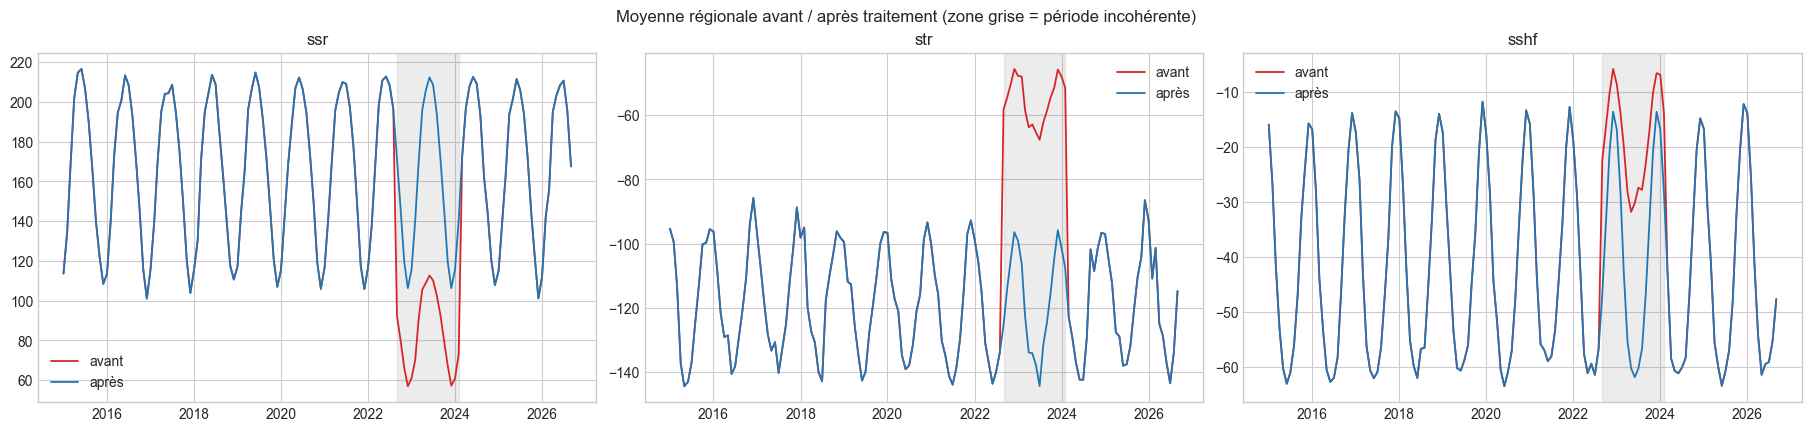

In [7]:
for v in V_ANOM:
    flat = ARR_ORIG[v].reshape(-1).copy(); flat[T_flat["win"]] = final_pred[v]
    ARR[v] = flat.reshape(T, N); df[v] = flat
df["imputed_rad"] = T_flat["win"]

wc = np.cos(np.deg2rad(df["lat"].values[:N]))
reg = lambda a: (a * wc).sum(1) / wc.sum()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), constrained_layout=True)
for ax, v in zip(axes, V_ANOM):
    ax.plot(times, reg(ARR_ORIG[v]), color="tab:red", lw=1.3, label="avant")
    ax.plot(times, reg(ARR[v]), color="tab:blue", lw=1.3, label="après")
    ax.axvspan(pd.Timestamp(ANOM_START+"-01"), pd.Timestamp(ANOM_END+"-01"), color="grey", alpha=.15)
    ax.set_title(v); ax.legend()
fig.suptitle("Moyenne régionale avant / après traitement (zone grise = période incohérente)"); plt.show()

**Lecture** : si la courbe « après » reprend le cycle saisonnier des autres années dans la zone grise, la période est cohérente avec le reste de la série. Limite assumée : les valeurs imputées sont des estimations (climatologie ou modèle), elles ne contiennent pas la vraie variabilité de ces 18 mois, d'où le drapeau `imputed_rad`.

## Étape 3 — Cohérence physique (cours : *Accuracy / Consistency*)
Règles : point de rosée ≤ température ; précipitation, ruissellement, rayonnement solaire, vitesse du vent ≥ 0. Une violation est une erreur de donnée, pas un événement climatique.

In [8]:
checks = {"d2m > t2m": int((df["d2m"] > df["t2m"] + 1e-6).sum()), "tp < 0": int((df["tp"] < 0).sum()), "ro < 0": int((df["ro"] < 0).sum()),
          "ssr < 0": int((df["ssr"] < 0).sum()), "wind10_speed < 0": int((df["wind10_speed"] < 0).sum()),
          "slhf ≥ 0": int((df["slhf"] >= 0).sum())}
display(pd.Series(checks, name="violations").to_frame().T)
if checks["d2m > t2m"]:
    pct = 100*checks["d2m > t2m"]/len(df); print(f"d2m > t2m : {pct:.3f} % → écrêtage d2m = min(d2m, t2m) (saturation)")
    df["d2m"] = np.minimum(df["d2m"], df["t2m"])

,d2m > t2m,tp < 0,ro < 0,ssr < 0,wind10_speed < 0,slhf ≥ 0
violations,0,0,0,0,0,0


## Étape 4 — Asymétrie et outliers (constats B et C)

**Les valeurs extrêmes de `tp`, `slhf`/`e` sont-elles des erreurs ?** Non : fortes précipitations et forte évaporation sont des événements climatiques réels (zones côtières, orages), pas des fautes de saisie. Supprimer ces lignes (« delete value and handle as missing ») retirerait ~15 % des échantillons et surtout les cas rares utiles à la prévision. Le cours propose alors la **transformation** (log, racine) ou des modèles robustes aux outliers (arbres, RF). Comme le projet utilise aussi **KNN et SVM**, sensibles à l'échelle et aux queues lourdes, on transforme :

- `tp` → `log1p(tp)` (valeurs ≥ 0 avec beaucoup de petites valeurs) ;
- `slhf` → `log1p(−slhf)` (toujours négative, queue à gauche) ;
- `ro` n'est pas transformée : elle sera éliminée à l'étape 5 (et `log1p` est de toute façon monotone).

,skew avant,skew après,% outliers IQR avant,% outliers IQR après
tp,5.79,3.36,15.12,14.42
slhf,-4.21,1.39,16.46,9.71


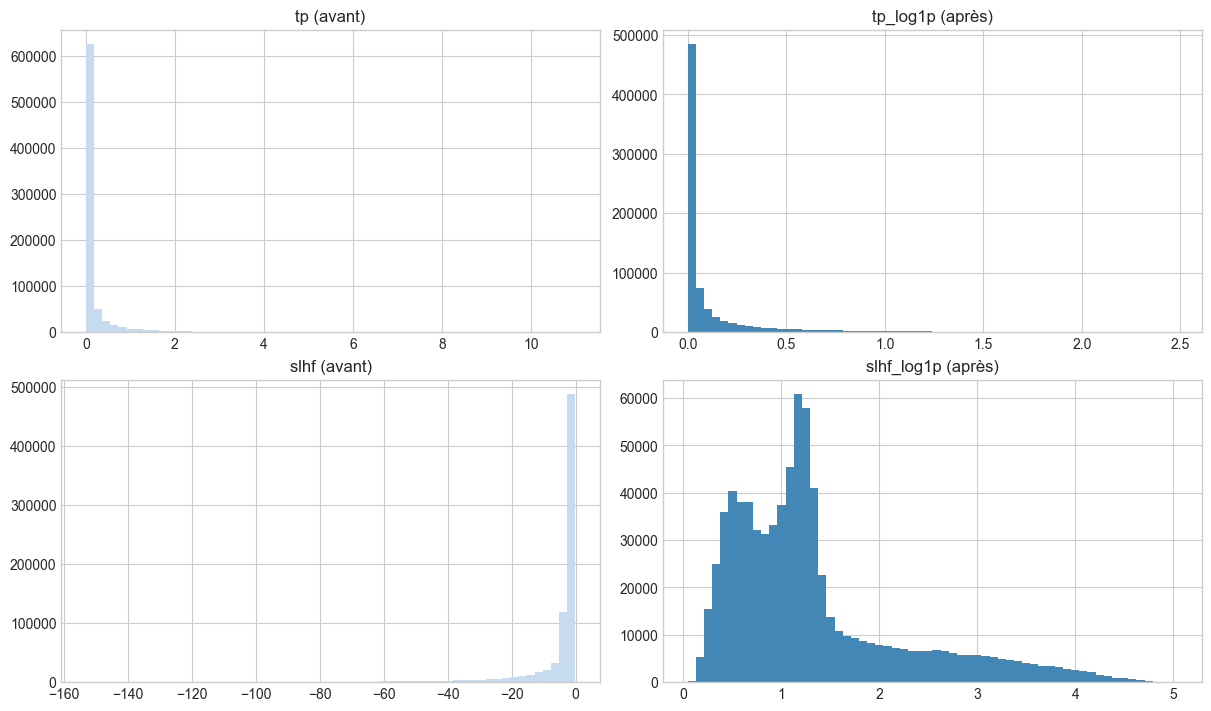

In [9]:
df["tp_log1p"]   = np.log1p(df["tp"])
df["slhf_log1p"] = np.log1p(-df["slhf"])
sk = pd.DataFrame({"skew avant": [stats.skew(df["tp"]), stats.skew(df["slhf"])],
                   "skew après": [stats.skew(df["tp_log1p"]), stats.skew(df["slhf_log1p"])]}, index=["tp", "slhf"])
def iqr_pct(x):
    q1, q3 = np.percentile(x, [25, 75]); i = q3 - q1; return 100*((x < q1-1.5*i) | (x > q3+1.5*i)).mean()
sk["% outliers IQR avant"] = [iqr_pct(df["tp"]), iqr_pct(df["slhf"])]
sk["% outliers IQR après"] = [iqr_pct(df["tp_log1p"]), iqr_pct(df["slhf_log1p"])]
display(sk.round(2))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for (r, (a, b)) in enumerate([("tp", "tp_log1p"), ("slhf", "slhf_log1p")]):
    axes[r, 0].hist(df[a], bins=60, color="#c6dbef"); axes[r, 0].set_title(f"{a} (avant)")
    axes[r, 1].hist(df[b], bins=60, color="#4287b5"); axes[r, 1].set_title(f"{b} (après)")
plt.show()

## Étape 5 — Sélection de variables (constats B et E) sur données **nettoyées**
Règles du cours (*What features to eliminate*) appliquées **dans cet ordre** : (1) variance faible ; (2) forte corrélation (> 90 %, formule **Spearman** car aucune variable n'est normale) ; (3) > 50 % de NaN ; (4) non pertinente pour la cible.

Pour départager deux variables corrélées on garde celle qui est la plus liée à la **cible** (classe de `t2m(t+1)`, 3 intervalles de même largeur), mesurée par l'**information mutuelle** (filtre) et l'**importance Random Forest** (embedded). Il faut donc d'abord construire la cible.

Seuils (°C) : [ 0.91 14.33 27.74 41.16]


,information mutuelle,importance RF
t2m,0.5051,0.2102
str,0.4832,0.1973
ssr,0.4795,0.1954
sshf,0.3843,0.1100
e,0.2617,0.0419
slhf_log1p,0.2608,0.0434
tp_log1p,0.1363,0.0184
ro,0.0697,0.0232
d2m,0.0468,0.0513
u10,0.0387,0.0210


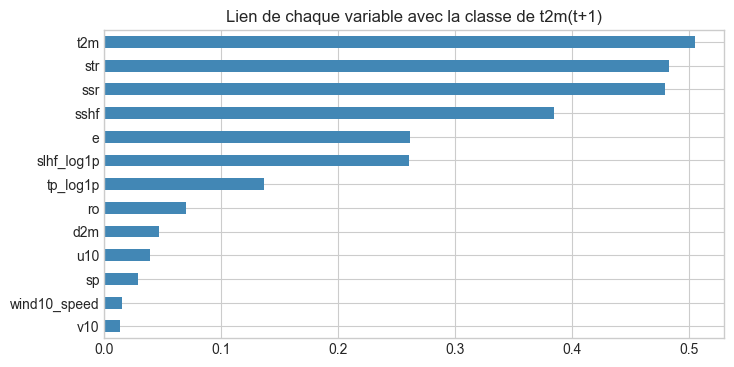

In [10]:
t2m_next = np.vstack([ARR["t2m"][1:], np.full((1, N), np.nan)]).reshape(-1)
df["t2m_next"] = t2m_next
EDGES = np.linspace(np.nanmin(t2m_next), np.nanmax(t2m_next), 4)
df["classe"] = pd.cut(df["t2m_next"], bins=EDGES, labels=["Froid", "Modéré", "Chaud"], include_lowest=True)
print("Seuils (°C) :", np.round(EDGES, 2))

CAND = ["d2m", "t2m", "slhf_log1p", "ssr", "str", "sshf", "ro", "e", "u10", "v10", "sp", "tp_log1p", "wind10_speed"]
dd = df.dropna(subset=["classe"]); samp = dd.sample(80_000, random_state=42)
mi = pd.Series(mutual_info_classif(samp[CAND], samp["classe"].astype(str), random_state=42), index=CAND, name="information mutuelle")
rf = RandomForestClassifier(150, max_depth=12, n_jobs=-1, random_state=42).fit(samp[CAND], samp["classe"].astype(str))
imp = pd.Series(rf.feature_importances_, index=CAND, name="importance RF")
score = pd.concat([mi, imp], axis=1).sort_values("information mutuelle", ascending=False)
display(score.round(4))
fig, ax = plt.subplots(figsize=(8, 4)); score["information mutuelle"].plot.barh(ax=ax, color="#4287b5"); ax.invert_yaxis()
ax.set_title("Lien de chaque variable avec la classe de t2m(t+1)"); plt.show()

Variables éliminées :


,raison
ro,variance 0.0014 < 0.01 ; 19.4 % de zéros ; ske...
e,"ρ(slhf_log1p,e) = -1.00 > 0.90 ; on garde slhf..."
sshf,"ρ(ssr,sshf) = -0.95 > 0.90 ; on garde ssr : mo..."


Variables conservées : ['d2m', 't2m', 'slhf_log1p', 'ssr', 'str', 'u10', 'v10', 'sp', 'tp_log1p', 'wind10_speed']
Contrôle : |ρ| max entre variables conservées = 0.81 (< 0.90)


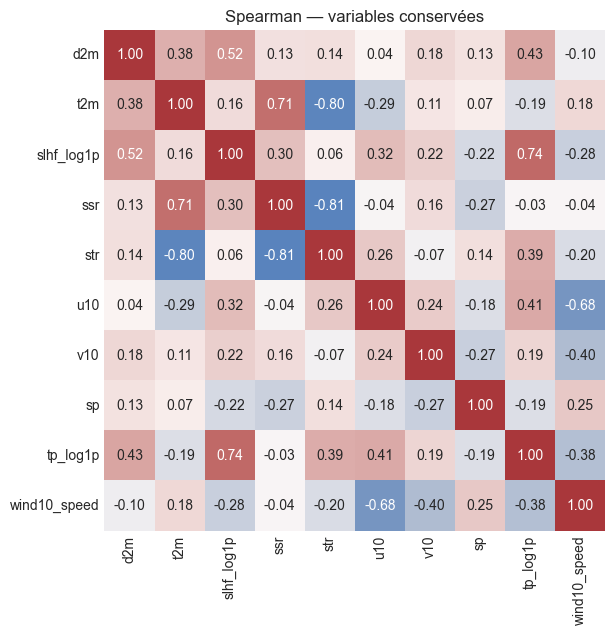

In [11]:
dropped = {}
# (1) variance faible — seuil du cours (0.01) en unités d'origine
for v in ["d2m","t2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp","wind10_speed"]:
    col = {"slhf": "slhf_log1p", "tp": "tp_log1p"}.get(v, v)
    if df[v].var() < 0.01:
        dropped[col] = f"variance {df[v].var():.2g} < 0.01 ; {100*(df[v]==0).mean():.1f} % de zéros ; skew {stats.skew(df[v]):.0f}"

# (2) corrélations > 0.90 (Spearman) sur les colonnes restantes, par |r| décroissant
rank = df[CAND].rank().corr()
pairs = [(a, b, rank.loc[a, b]) for i, a in enumerate(CAND) for b in CAND[i+1:] if abs(rank.loc[a, b]) > 0.90]
DERIVED_FIRST = {"e"}                                    # e est proportionnelle à slhf (flux ÷ chaleur latente)
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    if a in dropped or b in dropped: continue
    if a in DERIVED_FIRST or b in DERIVED_FIRST: d = a if a in DERIVED_FIRST else b; why = "variable dérivée de l'autre"
    else: d = a if (mi[a], imp[a]) < (mi[b], imp[b]) else b; why = "moins liée à la cible (MI, importance RF)"
    k = b if d == a else a
    dropped[d] = f"ρ({a},{b}) = {r:.2f} > 0.90 ; on garde {k} : {why}"

# (3) > 50 % de NaN
for v in CAND:
    if df[v].isna().mean() > 0.5: dropped[v] = "> 50 % de NaN"

KEEP = [v for v in CAND if v not in dropped]
print("Variables éliminées :"); display(pd.Series(dropped, name="raison").to_frame())
print("Variables conservées :", KEEP)
rk = df[KEEP].rank().corr().values.copy(); np.fill_diagonal(rk, 0)
print(f"Contrôle : |ρ| max entre variables conservées = {np.abs(rk).max():.2f} (< 0.90)")
plt.figure(figsize=(8, 6.5)); sns.heatmap(df[KEEP].rank().corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, cbar=False)
plt.title("Spearman — variables conservées"); plt.show()

**Remarque sur la pertinence (critère 4)** : une variable peu liée à la cible *prise seule* (par exemple `sp`, qui reflète surtout l'altitude de la cellule) peut quand même aider en interaction avec les autres, surtout pour les arbres. On ne supprime donc pas sur ce seul critère ; la sélection par **wrapper** (RFE) ou l'importance du modèle final sera discutée à l'étape 2.

## Étape 6 — Variables dérivées, cible finale et réduction du volume

- **Variable dérivée** (cours : *derived features*) : le mois est cyclique (décembre est proche de janvier) ; un entier 1–12 imposerait un faux écart. On l'encode par `mois_sin` et `mois_cos`.
- **Lignes sans cible** : le dernier mois (2026-09) n'a pas de mois suivant ; ces lignes sont supprimées.
- **Réduction du volume** (*numerosity reduction*) : aucun doublon (clé cellule×mois vérifiée) ; le jeu complet est conservé, plus un **échantillon stratifié** (même proportion de classes) pour les modèles coûteux (SVM, KNN) afin de respecter le déséquilibre des classes (Froid ≈ 17 %).
- Le **scaling** n'est pas appliqué ici (voir plus haut).

In [12]:
df["mois_sin"] = np.sin(2*np.pi*df["month"]/12); df["mois_cos"] = np.cos(2*np.pi*df["month"]/12)
FEATURES = KEEP + ["mois_sin", "mois_cos"]
META = ["time", "cell", "lat", "lon", "year", "month", "n_sub", "imputed_rad"]
final = df.dropna(subset=["classe"])[META + FEATURES + ["t2m_next", "classe"]].reset_index(drop=True)
assert final[FEATURES].isna().sum().sum() == 0 and not final.duplicated(["cell", "time"]).any()
print(f"Dataset final : {final.shape[0]:,} lignes × {len(FEATURES)} variables explicatives")
print("Variables explicatives :", FEATURES)
print("Répartition des classes (%) :"); display((final["classe"].value_counts(normalize=True)*100).round(1).to_frame("%").T)

frac = 100_000 / len(final)
strat = final.groupby("classe", observed=True).sample(frac=frac, random_state=42)
print(f"Échantillon stratifié : {len(strat):,} lignes ; classes (%) :", (strat['classe'].value_counts(normalize=True)*100).round(1).to_dict())

def save(d, name):
    try: d.to_parquet(OUT/f"{name}.parquet"); return f"{name}.parquet"
    except Exception: d.to_csv(OUT/f"{name}.csv.gz", index=False); return f"{name}.csv.gz"
print("Fichiers :", save(final, "dataset_clean"), "|", save(strat, "dataset_clean_strat100k"))

Dataset final : 759,360 lignes × 12 variables explicatives
Variables explicatives : ['d2m', 't2m', 'slhf_log1p', 'ssr', 'str', 'u10', 'v10', 'sp', 'tp_log1p', 'wind10_speed', 'mois_sin', 'mois_cos']
Répartition des classes (%) :


classe,Modéré,Chaud,Froid
%,43.1,39.8,17.0


Échantillon stratifié : 100,000 lignes ; classes (%) : {'Modéré': 43.1, 'Chaud': 39.8, 'Froid': 17.0}
Fichiers : dataset_clean.parquet | dataset_clean_strat100k.parquet


## Journal des décisions (à joindre au rapport)

In [13]:
log = pd.DataFrame([
 (1, "Valeurs manquantes", "0 NaN après réduction ; 12 cellules brutes vides à la frontière nord ; zéros de ro = vrais zéros (Sud aride)",
  "Conserver les cellules de bord (moyenne des sous-cellules valides) + colonne n_sub ; zéros de ro conservés ; garde-fou d'interpolation",
  "Cours 04 : < 5 % de manquants → imputation classique ; Cours 03 : 0 peut coder un manquant, vérifié et écarté"),
 (2, "Incohérence temporelle ssr/str/sshf (2022-09→2024-02, 12,8 % des mois)", "Anomalie confirmée cellule par cellule",
  "Valeurs mises à NaN puis imputées (modèle prédictif ou climatologie, choisi par validation sur 2018-2019) ; drapeau imputed_rad",
  "Cours 04 : delete value and handle as missing ; > 5 % → modèle prédictif ; en 2e position car elle fausse toutes les statistiques suivantes"),
 (3, "Cohérence physique", "Règles d2m ≤ t2m, tp/ro/ssr ≥ 0, etc.", "Écrêtage de d2m à t2m si violation ; sinon rien",
  "Cours 04 : Accuracy / Consistency ; règle déterministe avant transformations"),
 (4, "Asymétrie et outliers (tp, slhf, e, ro)", "skew 5,8 / −4,2 ; ~15 à 16 % d'outliers IQR, événements réels",
  "Pas de suppression ; log1p(tp), log1p(−slhf)", "Cours 04 : transformation (log) plutôt que suppression ; KNN/SVM sensibles aux queues lourdes"),
 (5, "Sélection de variables", "ro var<0.01 ; |ρ|>0.90 : slhf–e, ro–tp, ssr–sshf",
  "Éliminer ro, e et l'une de ssr/sshf (la moins liée à la cible) ; recalcul sur données nettoyées", "Cours 04 : variance faible, corrélation > 90 %, Spearman car non normal"),
 (6, "Dérivation, cible, volume", "Mois cyclique ; dernier mois sans cible ; classes déséquilibrées",
  "mois_sin/cos ; suppression du dernier mois ; échantillon stratifié 100 k", "Cours 05 : derived features ; Cours 04 : stratified sampling"),
 (7, "Scaling et découpage train/test", "—", "Reportés à l'étape 2, dans les pipelines, ajustés sur le train seul", "Éviter toute fuite d'information"),
], columns=["Ordre", "Étape", "Constat EDA", "Décision", "Justification (cours)"])
log.to_csv(OUT/"decisions_pretraitement.csv", index=False)
display(log.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,Ordre,Étape,Constat EDA,Décision,Justification (cours)
0,1,Valeurs manquantes,0 NaN après réduction ; 12 cellules brutes vides à la frontière nord ; zéros de ro = vrais zéros (Sud aride),Conserver les cellules de bord (moyenne des sous-cellules valides) + colonne n_sub ; zéros de ro conservés ; garde-fou d'interpolation,"Cours 04 : < 5 % de manquants → imputation classique ; Cours 03 : 0 peut coder un manquant, vérifié et écarté"
1,2,"Incohérence temporelle ssr/str/sshf (2022-09→2024-02, 12,8 % des mois)",Anomalie confirmée cellule par cellule,"Valeurs mises à NaN puis imputées (modèle prédictif ou climatologie, choisi par validation sur 2018-2019) ; drapeau imputed_rad",Cours 04 : delete value and handle as missing ; > 5 % → modèle prédictif ; en 2e position car elle fausse toutes les statistiques suivantes
2,3,Cohérence physique,"Règles d2m ≤ t2m, tp/ro/ssr ≥ 0, etc.",Écrêtage de d2m à t2m si violation ; sinon rien,Cours 04 : Accuracy / Consistency ; règle déterministe avant transformations
3,4,"Asymétrie et outliers (tp, slhf, e, ro)","skew 5,8 / −4,2 ; ~15 à 16 % d'outliers IQR, événements réels","Pas de suppression ; log1p(tp), log1p(−slhf)",Cours 04 : transformation (log) plutôt que suppression ; KNN/SVM sensibles aux queues lourdes
4,5,Sélection de variables,"ro var<0.01 ; |ρ|>0.90 : slhf–e, ro–tp, ssr–sshf","Éliminer ro, e et l'une de ssr/sshf (la moins liée à la cible) ; recalcul sur données nettoyées","Cours 04 : variance faible, corrélation > 90 %, Spearman car non normal"
5,6,"Dérivation, cible, volume",Mois cyclique ; dernier mois sans cible ; classes déséquilibrées,mois_sin/cos ; suppression du dernier mois ; échantillon stratifié 100 k,Cours 05 : derived features ; Cours 04 : stratified sampling
6,7,Scaling et découpage train/test,—,"Reportés à l'étape 2, dans les pipelines, ajustés sur le train seul",Éviter toute fuite d'information
